# Customer Sales Analysis — Week 5
**Advanced data manipulation with pandas:** grouping and aggregation, multi-condition filtering, string and datetime operations, merging, and pivot tables.

The reusable logic lives in `src/`; this notebook walks through each step and shows the results. Run `python run_analysis.py` to regenerate every chart, table and the PDF report in one go.

In [1]:
import pandas as pd
from IPython.display import Image, display

from src import analysis, charts, data_prep, insights
import run_analysis

pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 20)

## Day 1 — Load and explore
Both files are checked for required columns; a clear error is raised if a file is missing or empty.

In [2]:
sales_raw = data_prep.load_csv('sales_data.csv', data_prep.SALES_COLUMNS)
churn_raw = data_prep.load_csv('data/customer_churn.csv', data_prep.CHURN_COLUMNS)
print('sales:', sales_raw.shape, '| churn:', churn_raw.shape)
print('missing values -> sales:', int(sales_raw.isna().sum().sum()), '| churn:', int(churn_raw.isna().sum().sum()))
sales_raw.head()

sales: (100, 7) | churn: (500, 9)
missing values -> sales: 0 | churn: 0


,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
0,2024-01-01,Phone,7,37300,CUST001,East,261100
1,2024-01-02,Headphones,4,15406,CUST002,North,61624
2,2024-01-03,Phone,2,21746,CUST003,West,43492
3,2024-01-04,Headphones,1,30895,CUST004,East,30895
4,2024-01-05,Laptop,8,39835,CUST005,North,318680


In [3]:
sales_raw.dtypes.to_frame('dtype').T

,Date,Product,Quantity,Price,Customer_ID,Region,Total_Sales
dtype,object,object,int64,int64,object,object,int64


In [4]:
churn_raw.describe().round(1)

,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.0,500.0,500.0,500.0,500.0
mean,36.5,113.6,4237.9,0.5,0.1
std,20.7,51.8,2260.6,0.5,0.3
min,1.0,20.0,159.0,0.0,0.0
25%,19.0,67.0,2237.2,0.0,0.0
50%,37.0,115.0,4182.5,0.0,0.0
75%,54.0,158.0,6266.8,1.0,0.0
max,71.0,199.0,7992.0,1.0,1.0


## Day 2 — Clean, string operations and date parts
* **String operations:** `.str.strip()`, `.str.title()`, `.str.upper()`, `.str.replace()`, `.str.contains()`
* **Datetime:** `.dt.year`, `.dt.month_name()`, `.dt.day`, `.dt.day_name()`, `.dt.isocalendar().week`

In [5]:
sales, clean_log = data_prep.clean_sales(sales_raw)
churn = data_prep.clean_churn(churn_raw)
print(clean_log)
sales[['Date', 'Year', 'Month', 'Month_Name', 'Day', 'Weekday', 'Week', 'Is_Weekend']].head()

{'rows_in': 100, 'missing_values': 0, 'duplicates_removed': 0, 'invalid_rows_removed': 0, 'totals_recomputed': 0, 'rows_out': 100}


,Date,Year,Month,Month_Name,Day,Weekday,Week,Is_Weekend
0,2024-01-01,2024,2024-01,January,1,Monday,1,False
1,2024-01-02,2024,2024-01,January,2,Tuesday,1,False
2,2024-01-03,2024,2024-01,January,3,Wednesday,1,False
3,2024-01-04,2024,2024-01,January,4,Thursday,1,False
4,2024-01-05,2024,2024-01,January,5,Friday,1,False


In [6]:
# String operations on the churn text columns
churn[['Contract', 'PaymentMethod', 'Fixed_Term', 'Auto_Pay', 'Tenure_Band']].head()

,Contract,PaymentMethod,Fixed_Term,Auto_Pay,Tenure_Band
0,One year,Credit Card,True,True,0-6 months
1,Month-to-month,Electronic Check,False,False,13-24 months
2,Two year,Credit Card,True,True,25-48 months
3,Month-to-month,Electronic Check,False,False,49-72 months
4,One year,Electronic Check,True,False,13-24 months


### Building `customer_data.csv` and merging
> **Important:** `sales_data.csv` and `customer_churn.csv` share **no customer key** (CUST001… vs C00001…). To practise merging, `customer_data.csv` links the first 100 churn profiles to CUST001–CUST100 **in order**. This is a *simulated* link, so any finding from the merged table is **illustrative only**. Churn/retention findings later use the full 500-customer file and are real.

In [7]:
prepared = run_analysis.load_and_prepare('.')
customers, merged = prepared['customers'], prepared['merged']
print('customer_data rows:', len(customers), '| merged rows:', len(merged), '| unmatched:', prepared['unmatched'])
merged[['Customer_ID', 'Product', 'Region', 'Total_Sales', 'Contract', 'Tenure', 'Churn']].head()

INFO: Sales: 100 rows | churn: 500 customers | merged: 100 rows (0 unmatched)


customer_data rows: 100 | merged rows: 100 | unmatched: 0


,Customer_ID,Product,Region,Total_Sales,Contract,Tenure,Churn
0,CUST001,Phone,East,261100,One year,6,0
1,CUST002,Headphones,North,61624,Month-to-month,21,0
2,CUST003,Phone,West,43492,Two year,27,0
3,CUST004,Headphones,East,30895,Month-to-month,53,0
4,CUST005,Laptop,North,318680,One year,16,0


## Day 3 — Customer analysis
Customer value = revenue per customer over the period. Each customer placed exactly one order.

In [8]:
results = analysis.run_all(sales, churn, merged)
print('Top-10 customer share of revenue:', results['top10_share'], '%')
results['customer_value'].head(10)

Top-10 customer share of revenue: 27.1 %


,Revenue,Orders,Units,Region,Product,Rank,Cumulative_Share_%
Customer_ID,,,,,,,
CUST016,373932,1,9,South,Phone,1,3.0
CUST007,363870,1,9,South,Laptop,2,6.0
CUST083,350888,1,8,North,Laptop,3,8.8
CUST073,349510,1,7,West,Headphones,4,11.6
CUST020,333992,1,8,North,Laptop,5,14.3
CUST084,324144,1,8,South,Phone,6,17.0
CUST070,318762,1,9,South,Laptop,7,19.5
CUST005,318680,1,8,North,Laptop,8,22.1
CUST065,312564,1,7,South,Phone,9,24.6


In [9]:
results['region']

,Revenue,Orders,Customers,Avg_Order,Max_Order,Share_%
Region,,,,,,
North,3983635,28,28,142273.0,350888,32.2
South,3737852,27,27,138439.0,373932,30.2
East,2519639,19,19,132613.0,261100,20.4
West,2123922,26,26,81689.0,349510,17.2


## Day 4 — Sales patterns
Three+ aggregation styles: named `agg()`, `transform()`, `pct_change()` and `rank()`.

In [10]:
results['monthly']

,Revenue,Orders,Units,Active_Days,Revenue_per_Day,MoM_Growth_%
Month,,,,,,
2024-01,4120524,31,147,31,132920.0,NaN
2024-02,2656050,29,112,29,91588.0,-35.5
2024-03,4485006,31,175,31,144678.0,68.9
2024-04,1103468,9,44,9,122608.0,-75.4


In [11]:
results['product']

,Revenue,Units,Orders,Avg_Price,Revenue_Rank,Units_Rank
Product,,,,,,
Laptop,3889210,136,24,27652.0,1,1
Tablet,2884340,127,26,24177.0,2,2
Phone,2859394,101,20,27379.0,3,3
Headphones,1384033,48,15,28692.0,4,5
Monitor,1348071,66,15,20710.0,5,4


In [12]:
results['weekday']

,Revenue,Orders,Avg_Order
Weekday,,,
Monday,1949322,15,129955.0
Tuesday,2520099,15,168007.0
Wednesday,1639017,14,117073.0
Thursday,927084,14,66220.0
Friday,1642948,14,117353.0
Saturday,1681286,14,120092.0
Sunday,2005292,14,143235.0


In [13]:
analysis.add_order_share_within_region(sales)[['Customer_ID', 'Region', 'Total_Sales', 'Share_of_Region_%']].sort_values('Share_of_Region_%', ascending=False).head()

,Customer_ID,Region,Total_Sales,Share_of_Region_%
72,CUST073,West,349510,16.46
42,CUST043,West,260100,12.25
0,CUST001,East,261100,10.36
15,CUST016,South,373932,10.00
6,CUST007,South,363870,9.73


### Multi-condition filtering (AND / OR / NOT)

In [14]:
hv = results['high_value']
print('AND  - orders >= ₹2,00,000 in North or South:', len(hv))
print('OR   - Laptop orders or 8+ units:', len(results['laptop_or_bulk']))
print('NOT  - weekend orders > ₹1,50,000 excluding Headphones:', len(results['weekend_large']))
hv[['Date', 'Product', 'Region', 'Quantity', 'Total_Sales']].head()

AND  - orders >= ₹2,00,000 in North or South: 14
OR   - Laptop orders or 8+ units: 36
NOT  - weekend orders > ₹1,50,000 excluding Headphones: 10


,Date,Product,Region,Quantity,Total_Sales
15,2024-01-16,Phone,South,9,373932
6,2024-01-07,Laptop,South,9,363870
82,2024-03-23,Laptop,North,8,350888
19,2024-01-20,Laptop,North,8,333992
83,2024-03-24,Phone,South,8,324144


## Day 5 — Pivot tables, cross-selling proxy and retention

In [15]:
results['region_product']

Product,Headphones,Laptop,Monitor,Phone,Tablet,Total
Region,,,,,,
East,288361,221946,642870,506828,859634,2519639
North,107091,1798206,397100,489284,1191954,3983635
South,512168,1373120,39924,1471428,341212,3737852
West,476413,495938,268177,391854,491540,2123922
Total,1384033,3889210,1348071,2859394,2884340,12365048


In [16]:
results['month_product_units']

Product,Headphones,Laptop,Monitor,Phone,Tablet
Month,,,,,
2024-01,13,58,10,33,33
2024-02,4,10,29,34,35
2024-03,19,62,26,34,34
2024-04,12,6,1,0,25


**Cross-selling:** with one order per customer, products bought together cannot be measured. Region × product *lift* shows where each product over- or under-sells relative to the overall mix.

In [17]:
results['affinity']

Product,Headphones,Laptop,Monitor,Phone,Tablet
Region,,,,,
East,1.02,0.28,2.34,0.87,1.46
North,0.24,1.44,0.91,0.53,1.28
South,1.22,1.17,0.10,1.70,0.39
West,2.00,0.74,1.16,0.80,0.99


### Retention (full 500-customer churn data — real)

In [18]:
results['churn_kpis']

{'customers': 500,
 'churned': 53,
 'churn_rate_%': 10.6,
 'retention_rate_%': 89.4,
 'max_tenure_of_churned': 11,
 'avg_tenure_churned': 6.0,
 'avg_tenure_retained': 40.2,
 'avg_monthly_charge': 113.6}

In [19]:
results['churn_contract']

,Customers,Churned,Avg_Monthly,Churn_Rate_%,Retention_%
Contract,,,,,
Month-to-month,170,35,112.8,20.6,79.4
One year,186,8,114.0,4.3,95.7
Two year,144,10,114.1,6.9,93.1


In [20]:
results['contract_tenure']

Contract,Month-to-month,One year,Two year
Tenure_Band,,,
0-6 months,100.0,35.7,30.8
7-12 months,100.0,25.0,60.0
13-24 months,0.0,0.0,0.0
25-48 months,0.0,0.0,0.0
49-72 months,0.0,0.0,0.0


In [21]:
print('At-risk active customers:', len(results['at_risk']))
results['at_risk'][['CustomerID', 'Tenure', 'Contract', 'PaymentMethod', 'MonthlyCharges']].head()

At-risk active customers: 54


,CustomerID,Tenure,Contract,PaymentMethod,MonthlyCharges
455,C00456,1,Two year,Bank Transfer,30
157,C00158,1,Two year,Bank Transfer,86
496,C00497,2,Two year,Bank Transfer,49
413,C00414,2,Two year,Electronic Check,158
492,C00493,2,One year,Credit Card,114


### Merged data (illustrative)

In [22]:
results['merged_contract']

,Customers,Revenue,Avg_Order,Churned,Revenue_Share_%
Contract,,,,,
One year,36,5216183,144894.0,1,42.2
Month-to-month,35,3766277,107608.0,6,30.5
Two year,29,3382588,116641.0,3,27.4


## Day 6 — Dashboard charts

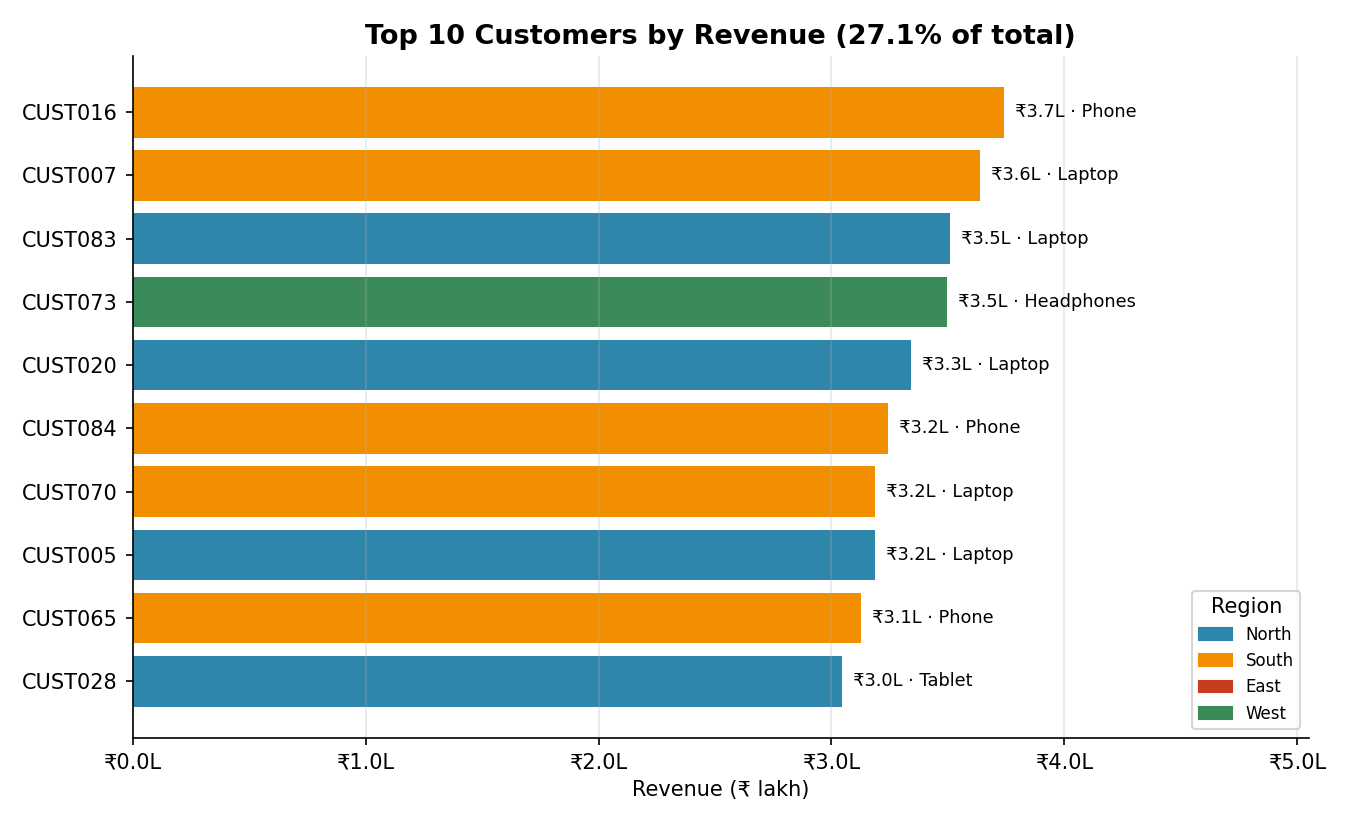

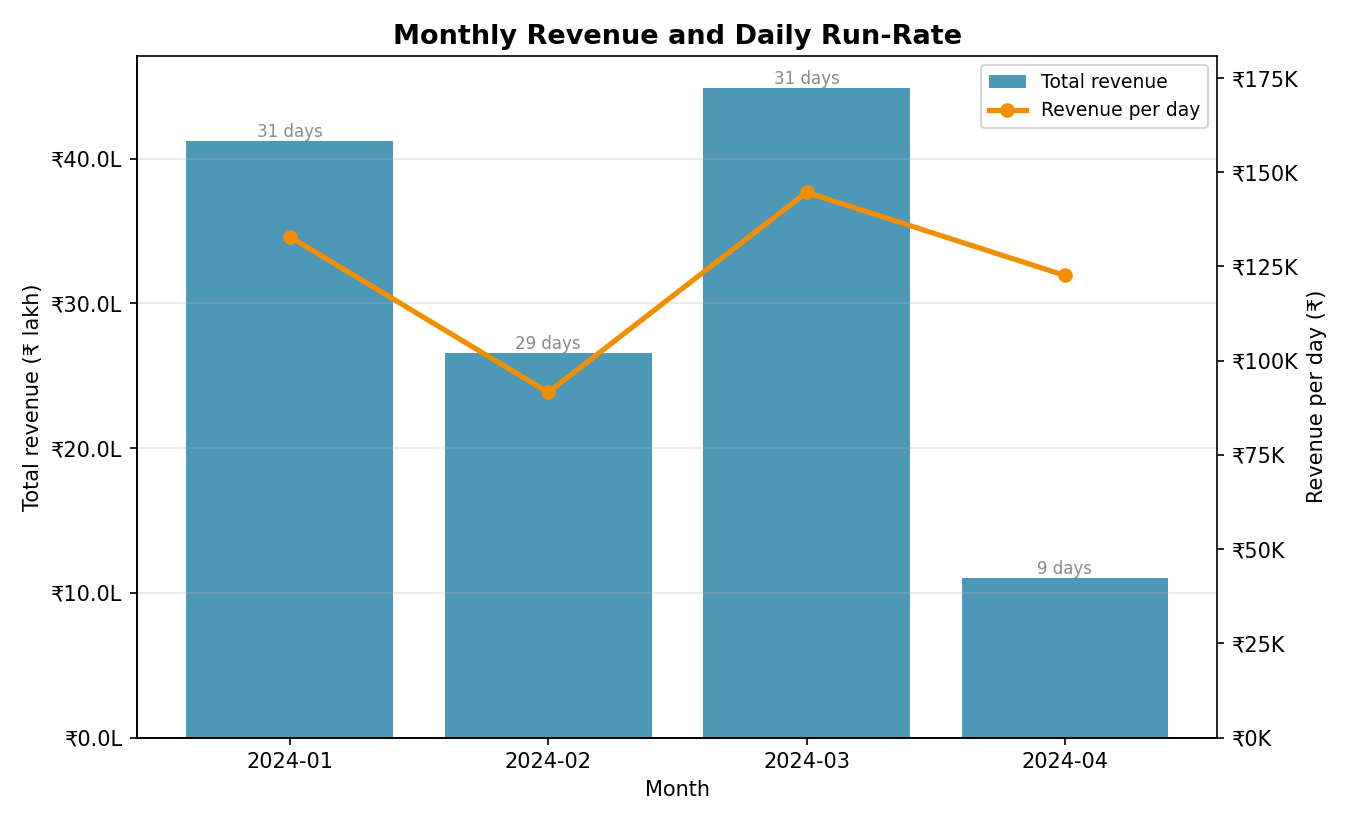

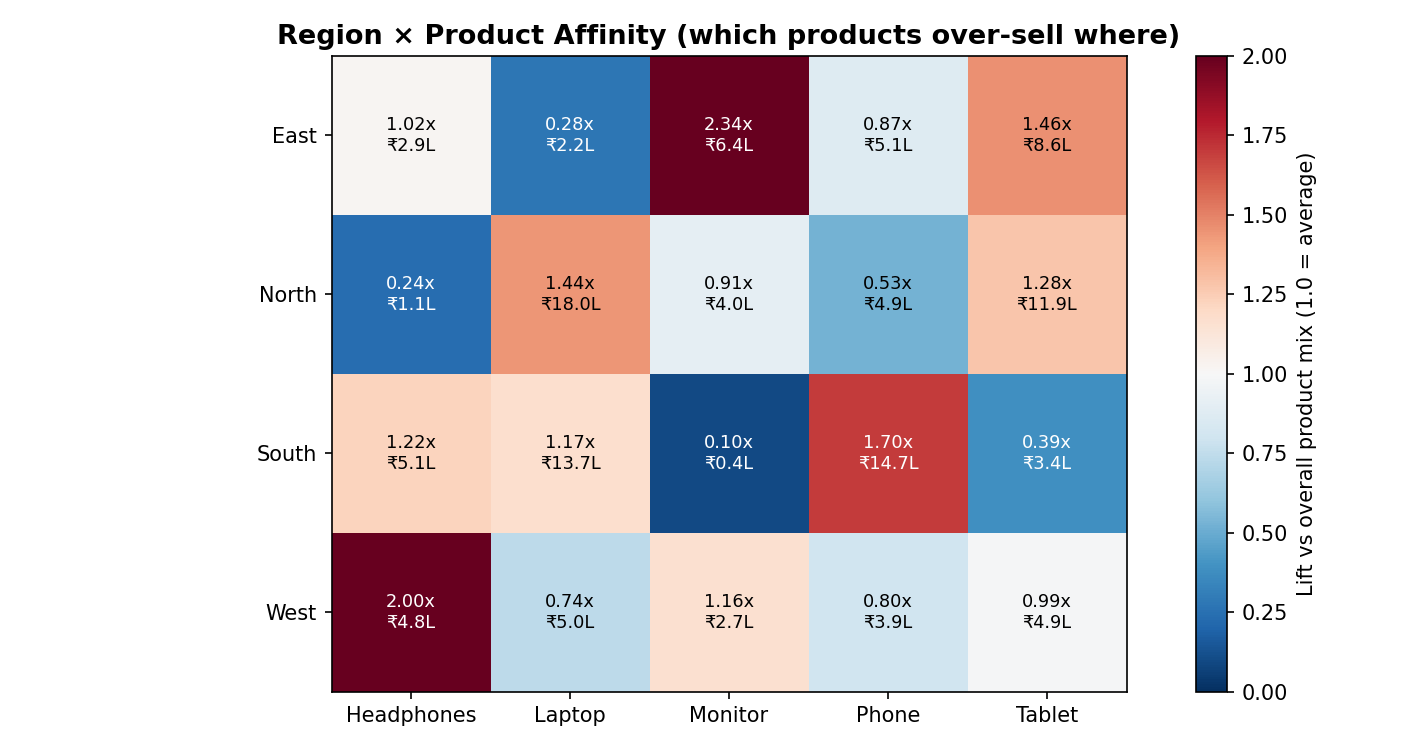

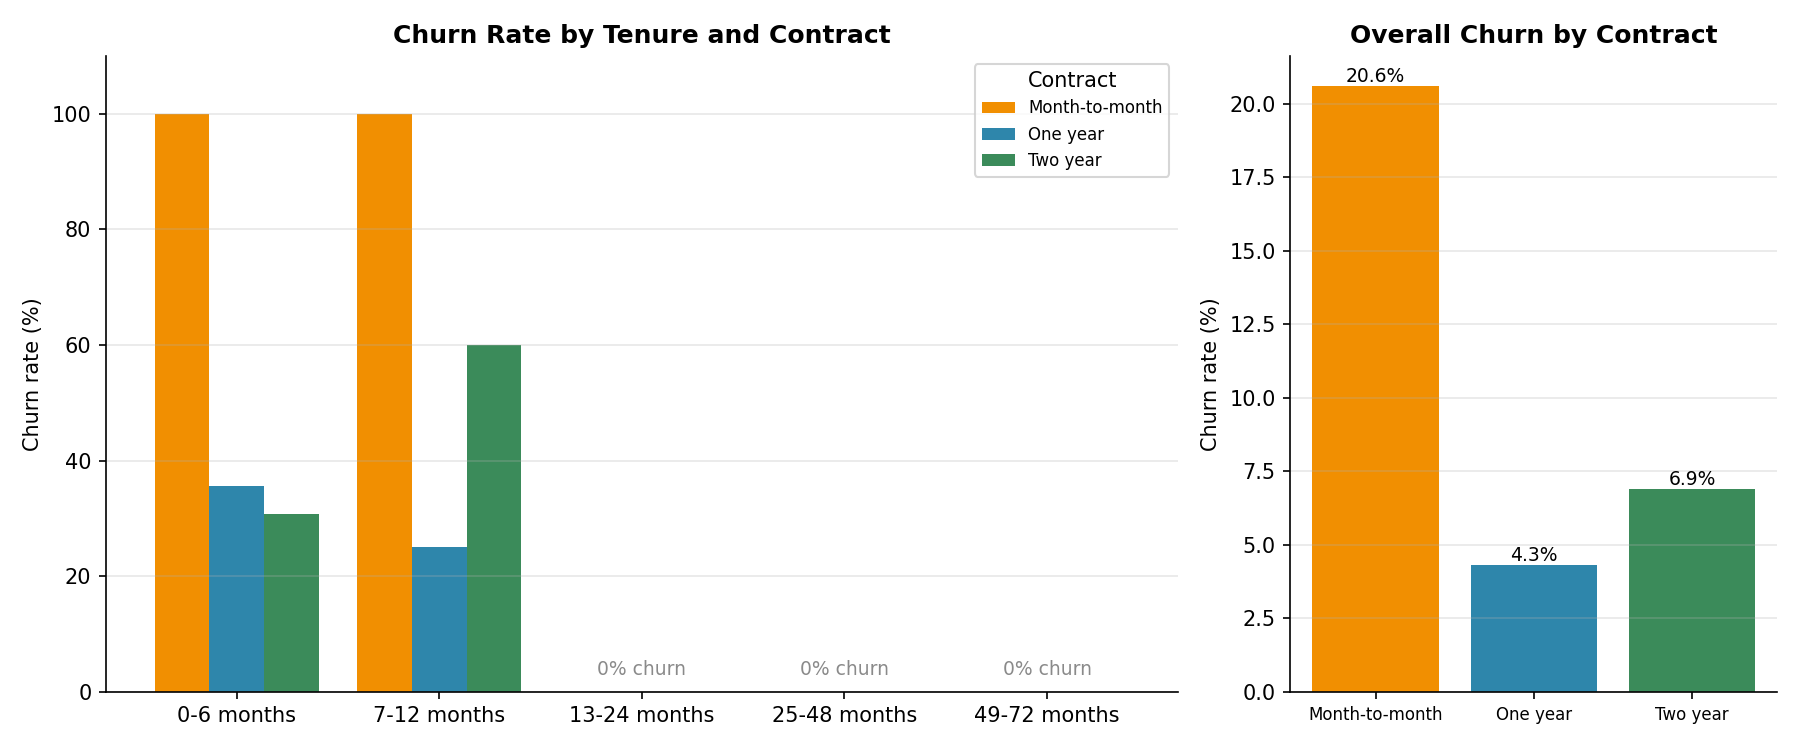

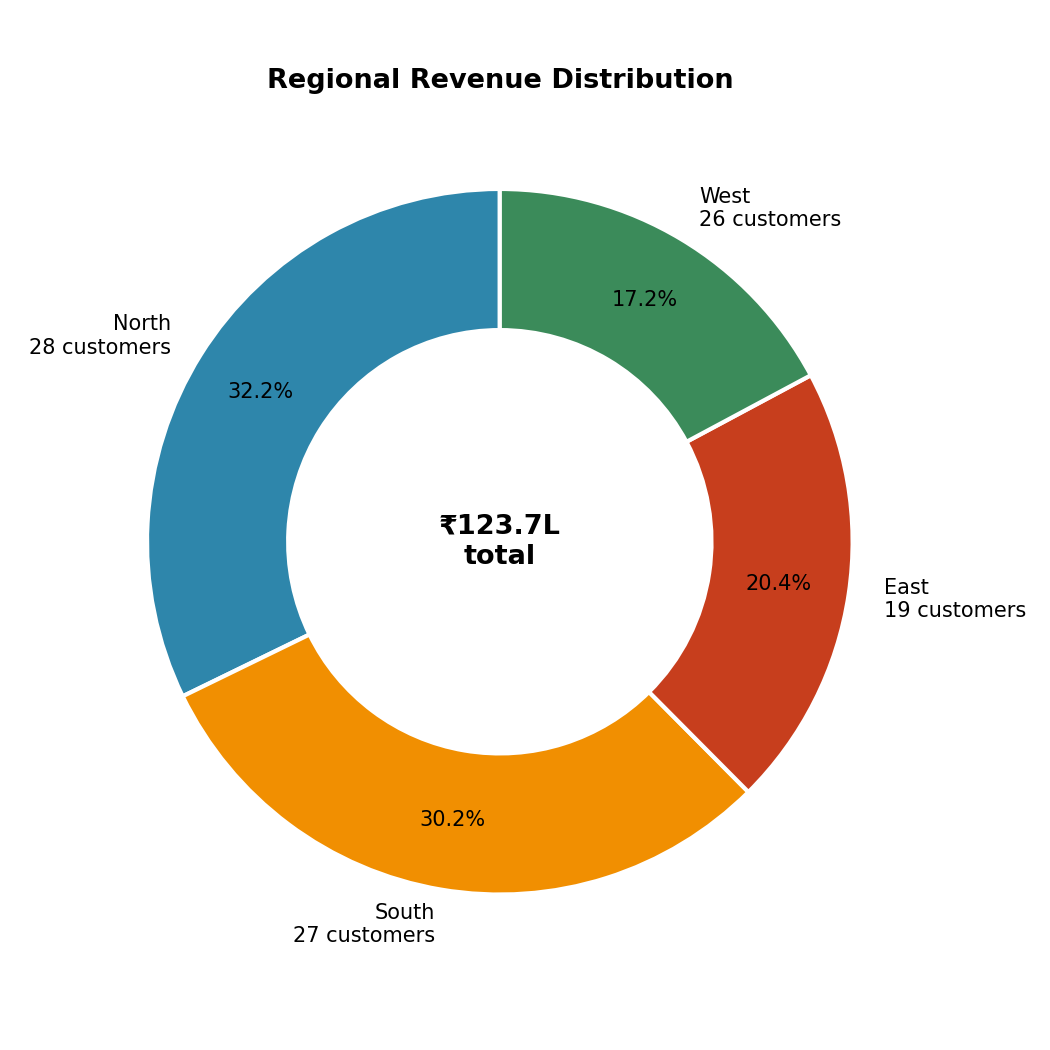

In [23]:
chart_paths = charts.make_all(results, 'visualizations')
for path in chart_paths:
    display(Image(filename=str(path), width=720))

## Day 7 — Insights and recommendations

In [24]:
for line in insights.sales_insights(results) + insights.churn_insights(results) + insights.merged_insights(results):
    print('•', line)
print('\nRecommendations:')
for line in insights.recommendations(results):
    print('→', line)

• Top customer CUST016 spent ₹373,932 (Phone, South). The top 10 customers bring in 27.1% of revenue - every customer placed exactly one order, so value comes from order size, not repeat buying.
• Laptop is the best-selling product by both revenue (₹3,889,210) and units (136).
• North and South generate 62.4% of revenue. West has 26 orders but the lowest average order (₹81,689 vs ₹123,650 overall).
• 2024-02 was the slowest full month: revenue per day was 37% below 2024-03.
• Strongest regional fit: Monitor in East sells at 2.34x its normal share; weakest: Monitor in South at 0.10x.
• Retention rate is 89.4% (53 of 500 customers churned, churn rate 10.6%).
• All churn happens early: no customer with tenure above 11 months churned, and customers in their first 12 months churn at 63.1%. Churned customers averaged 6.0 months of tenure vs 40.2 for retained customers.
• Month-to-month contracts churn at 20.6% - about 4x the fixed-term contracts. In this data every month-to-month customer in

In [25]:
out = run_analysis.run('.')  # regenerates charts, report_tables/ and analysis_report.pdf
print(out['pdf'])

INFO: Sales: 100 rows | churn: 500 customers | merged: 100 rows (0 unmatched)


INFO: Charts: 5 | PDF: analysis_report.pdf



              CUSTOMER SALES ANALYSIS REPORT
Total Revenue       : ₹12,365,048
Total Customers     : 100
Average Order Value : ₹123,650
Top Customer        : CUST016 - ₹373,932
Top-10 Share        : 27.1%
Retention Rate      : 89.4% (churn 10.6%, 500 customers)
------------------------------------------------------------
 * Top customer CUST016 spent ₹373,932 (Phone, South). The top 10 customers bring in 27.1% of revenue - every customer placed exactly one order, so value comes from order size, not repeat buying.
 * Laptop is the best-selling product by both revenue (₹3,889,210) and units (136).
 * North and South generate 62.4% of revenue. West has 26 orders but the lowest average order (₹81,689 vs ₹123,650 overall).
 * 2024-02 was the slowest full month: revenue per day was 37% below 2024-03.
 * Strongest regional fit: Monitor in East sells at 2.34x its normal share; weakest: Monitor in South at 0.10x.
 * Retention rate is 89.4% (53 of 500 customers churned, churn rate 10.6%).
 * Al